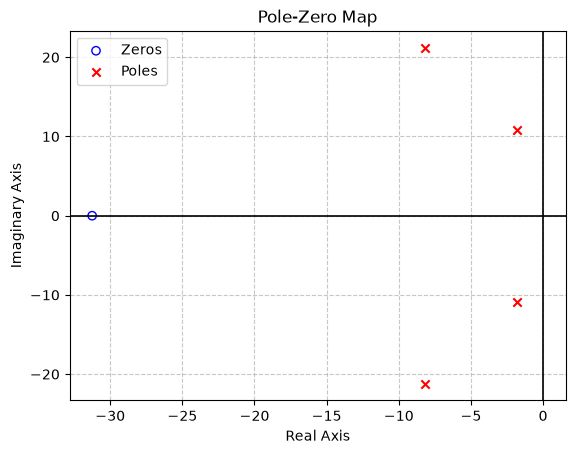

In [1]:
import matplotlib.pyplot as plt

zeros_real = [-31.25]
zeros_imag = [0]
poles_real = [-8.161, -8.161, -1.839, -1.839]
poles_imag = [21.209, -21.209, 10.846, -10.846]

plt.scatter(zeros_real, zeros_imag, marker='o', facecolors='none', edgecolors='blue', label='Zeros')
plt.scatter(poles_real, poles_imag, marker='x', color='red', label='Poles')

plt.axhline(0, color='black', linewidth=1.2)
plt.axvline(0, color='black', linewidth=1.2)
plt.grid(True, linestyle='--', alpha=0.7)
plt.xlabel('Real Axis')
plt.ylabel('Imaginary Axis')
plt.title('Pole-Zero Map')
plt.legend()

plt.savefig("pole-zero_map.png")
plt.show()

useful links
- https://math.stackexchange.com/questions/2335286/relation-between-poles-of-boldsymbolgs-and-eigenvalues-of-system
- https://www.youtube.com/watch?v=uLo64S-YNw8

`scipy.signal` is a part of SciPy that provides tools for working with signals and dynamic systems.
- step -- Finds the response of the system to a sudden step input
- lsim -- Simulates the system with a custom input signal
- bode -- Calculates the frequency response of a transfer function

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import StateSpace, step, lsim, bode
from scipy.linalg import eigvals

M1, M2 = 20.0, 8.0
b1, b2 = 120.0, 80.0
k1, k2 = 4000.0, 2500.0

`StateSpace()` -- Stores state space matrices as a system object for it to be simulated later

In [3]:
A = np.array([
    [0, 0, 1, 0],
    [0, 0, 0, 1],
    [-(k1 + k2)/M1, k2/M1, -(b1 + b2)/M1, b2/M1],
    [k2/M2, -k2/M2, b2/M2, -b2/M2]
])
B = np.array([[0], [0], [1/M1], [0]])
C = np.array([[1, 0, 0, 0], [0, 1, 0, 0]]) 
D = np.array([[0], [0]])

sys = StateSpace(A, B, C, D)

In [4]:
sys

StateSpaceContinuous(
array([[   0. ,    0. ,    1. ,    0. ],
       [   0. ,    0. ,    0. ,    1. ],
       [-325. ,  125. ,  -10. ,    4. ],
       [ 312.5, -312.5,   10. ,  -10. ]]),
array([[0.  ],
       [0.  ],
       [0.05],
       [0.  ]]),
array([[1., 0., 0., 0.],
       [0., 1., 0., 0.]]),
array([[0.],
       [0.]]),
dt: None
)

- `step()` calculated the response of a 1N force for the `sys` system in `T` time
- by multiplying step()'s response by 100, 100N step force can be simulated.

step() outputs, the response of the system for the step input and its corresponding time.

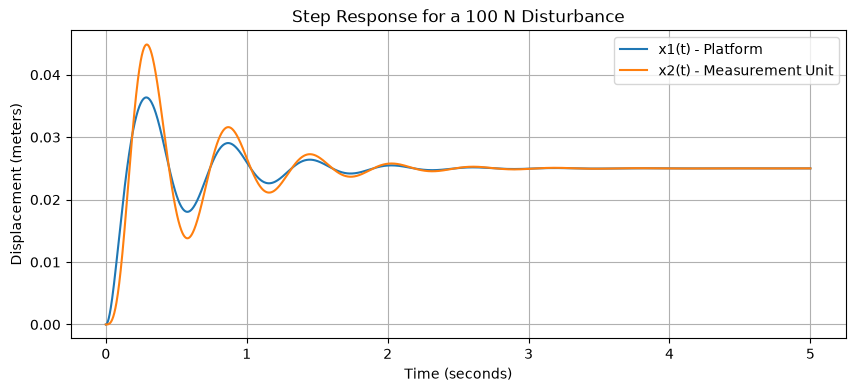

In [5]:
time = np.linspace(0, 5, 2000)

time_out, step_output = step(sys, T=time)

step_output = step_output * 100 

plt.figure(figsize=(10, 4))
plt.plot(time_out, step_output[:, 0], label='x1(t) - Platform')
plt.plot(time_out, step_output[:, 1], label='x2(t) - Measurement Unit')
plt.title('Step Response for a 100 N Disturbance')
plt.xlabel('Time (seconds)')
plt.ylabel('Displacement (meters)')
plt.legend()
plt.grid()

plt.savefig("step_response.png")
plt.show()

The eigen values of A from $\dot{x}=Ax+Bu$, is the pole of the system

$x(t)=5+4e^{−t}$
- The natural response is associated with the system's poles and usually forms the transient part -- $4e^{−t}$
- forced response is caused by the external input and usually determines the steady-state response. -- $5$

In [6]:
poles = eigvals(A)

natural_freqs_rad = np.abs(poles)
natural_freqs_hz = natural_freqs_rad / (2 * np.pi)
unique_fn = np.unique(np.round(natural_freqs_hz, 2))

print(f"The system's natural frequencies are: {unique_fn} Hz")

The system's natural frequencies are: [1.75 3.62] Hz


Poles are usually complex numbers: $p=−2+15j$


$p=σ+jω_d$
where:
- $(\sigma)$ → damping/decay information
- $(\omega_d)$ → oscillation-related information

Pole's magnitude is the undamped natural angular frequency: $\omega_n = |p|=\sqrt{σ^2+ω_d^2}$ Unit: rad/s

In [7]:
print("Poles:\n", poles)
print("Natural Frequencies in Hz:\n", natural_freqs_hz)

Poles:
 [-8.16070726+21.20948218j -8.16070726-21.20948218j
 -1.83929274+10.84610559j -1.83929274-10.84610559j]
Natural Frequencies in Hz:
 [3.61684389 3.61684389 1.75085632 1.75085632]


Since the poles are complex, the poles will contain conjugates.\
their absolute will be the same, thus using the `unique()`, duplicates can be ignored.\
and `round()` is used to round to 2 decimal points for easier demonstration

In [8]:
unique_fn

array([1.75, 3.62])

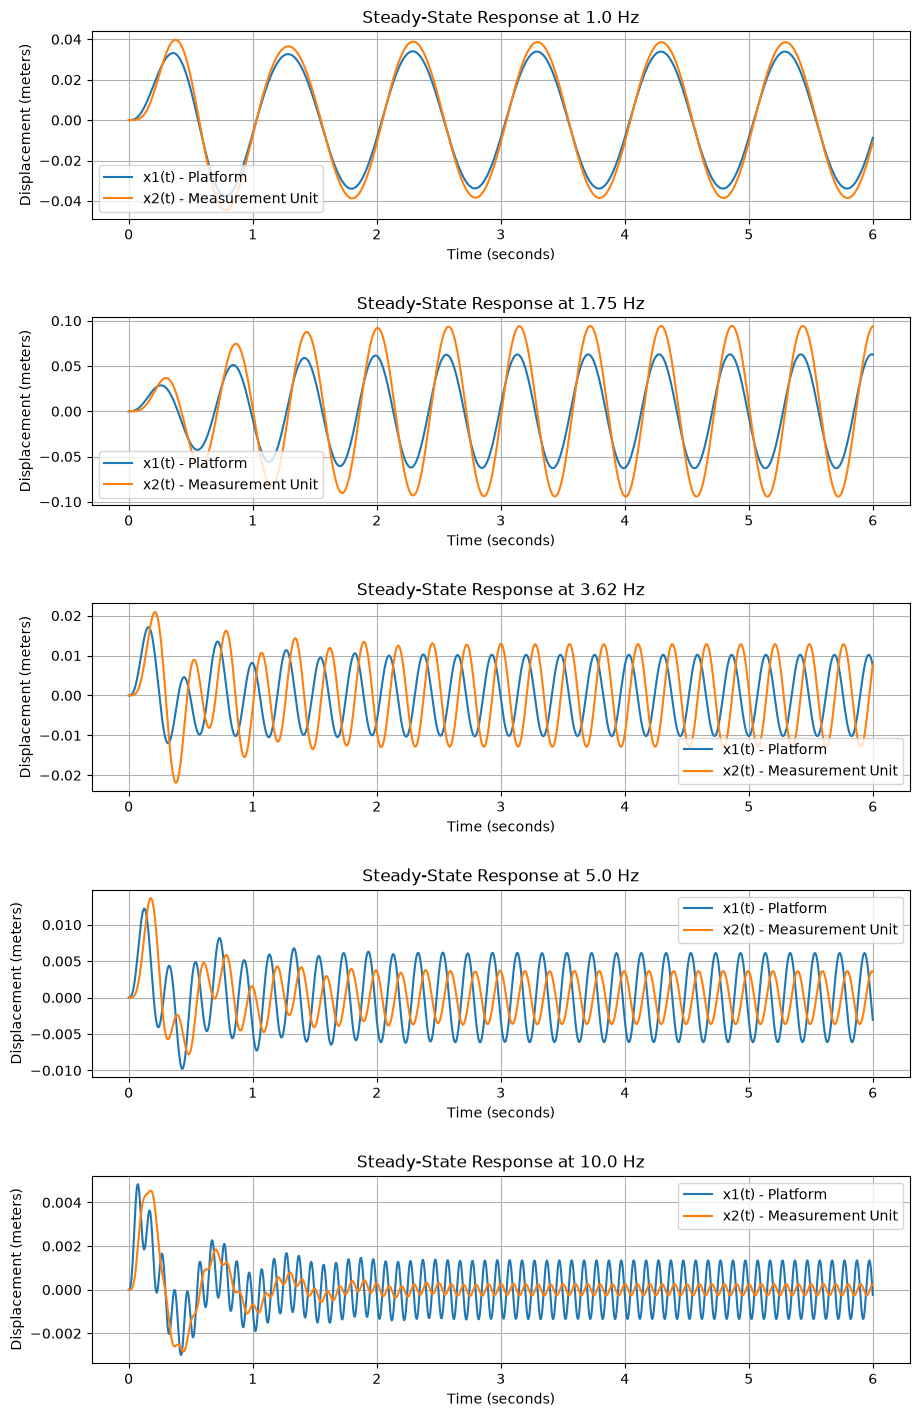

In [9]:
# 1Hz, Pole Freq 1, Pole Freq 2, 5Hz, 10Hz
test_frequencies = [1.0, unique_fn[0], unique_fn[1], 5.0, 10.0]

# A 6-second timeline.
time_sin = np.linspace(0, 6, 5000)

fig, axes = plt.subplots(
    5, 1,   # 5x1 Grid to place plots in
    figsize=(10, 15)
)
fig.tight_layout(pad=5.0)   # plots with padding of 0.5


for i, freq in enumerate(test_frequencies):
    # 100 N sinusoidal force: F(t) = 100 * sin(2*pi*f*t)
    force_sin = 100 * np.sin(2 * np.pi * freq * time_sin) 
    
    # lsim is "linear simulation". applies sine wave to the system
    time_out, output_sin, state_x = lsim(sys, U=force_sin, T=time_sin)
    
    steady_state_index = time_out > 0
    #0, 0.003, 0.006, ..., 9.99, 10.00, 10.003, ..., 15
    #False, False, False, ..., False, True, True, True, ...
    
    axes[i].plot(
        time_out[steady_state_index], # only the time values where steady_state_index is True
        output_sin[steady_state_index, 0], # Give me only 0th col the time values where steady_state_index is True
        label='x1(t) - Platform'
    )
    
    axes[i].plot(
        time_out[steady_state_index],
        output_sin[steady_state_index, 1], # only 1st col the time values where steady_state_index is True
        label='x2(t) - Measurement Unit'
    )
    
    axes[i].set_title(f'Steady-State Response at {freq} Hz')
    axes[i].set_xlabel('Time (seconds)')
    axes[i].set_ylabel('Displacement (meters)')
    axes[i].legend()
    axes[i].grid()
    
plt.savefig("responses.png")
plt.show()

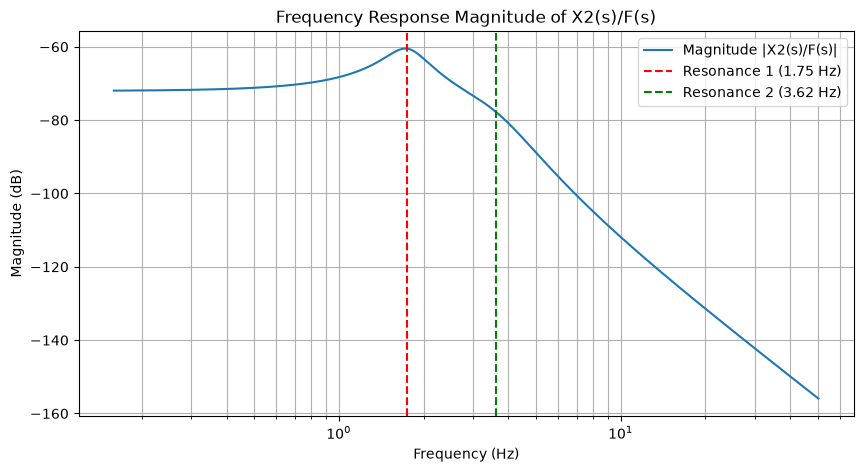

In [10]:
from scipy.signal import TransferFunction

# from the Numerator
num = [b2, k2]

# from the Denominator the two polynomials
poly1 = [M1, b1+b2, k1+k2]
poly2 = [M2, b2, k2]

# np.convolve multiplies the two polynomials together algebraically
poly_mult = np.convolve(poly1, poly2)

# Create the subtraction term: (b2*s + k2)^2 = b2^2*s^2 + 2*b2*k2*s + k2^2
poly_sub = [b2**2, 2*b2*k2, k2**2]

# Subtract it from the last 3 terms of our multiplied polynomial
den = np.copy(poly_mult)
den[-3:] = den[-3:] - poly_sub

# Transfer Function of the system
sys_tf = TransferFunction(num, den)

# the Bode Plot
w = np.logspace(0, 2.5, 2000) 
w, magnitude, phase = bode(sys_tf, w=w)
freq_hz_bode = w / (2 * np.pi)

plt.figure(figsize=(10, 5))
plt.plot(freq_hz_bode, magnitude, label='Magnitude |X2(s)/F(s)|')

# Draw vertical lines at our previously calculated natural frequencies
plt.axvline(unique_fn[0], color='red', linestyle='--', label=f'Resonance 1 ({unique_fn[0]} Hz)')
plt.axvline(unique_fn[1], color='green', linestyle='--', label=f'Resonance 2 ({unique_fn[1]} Hz)')

plt.title('Frequency Response Magnitude of X2(s)/F(s)')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude (dB)')
plt.xscale('log') 
plt.legend()
plt.grid(which='both')

plt.savefig("bode.png")
plt.show()